# 05 — Topic-Aware Text Summarization + Evaluasi ROUGE

**Proyek:** Analisis Dinamika Topik Pemberitaan Generative AI pada Media Online Indonesia Menggunakan BERTopic

**Video penjelasan:** `<<TEMPEL LINK VIDEO DI SINI>>`

Notebook ini menjawab Task 5. Untuk **setiap kelas** dibuat ringkasan yang disusun **per topik** hasil
notebook 04, sehingga setiap topik utama pasti terwakili (*topic coverage*). Ringkasan dievaluasi
dengan ROUGE dan dibandingkan dengan ringkasan yang **tidak** sadar-topik untuk menunjukkan bahwa
pendekatan sadar-topik memang memperbaiki cakupan topik.

In [1]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
import re, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from rouge_score import rouge_scorer
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore")
ROOT = Path.cwd()   # jalankan notebook dari folder repo
SCRAPED, RES, MODELS, FIG = ROOT / "scraped", ROOT / "results", ROOT / "models", ROOT / "figures"
for _d in (SCRAPED, RES, MODELS, FIG):
    _d.mkdir(exist_ok=True)


def tokenize(text):
    """Tokenisasi sederhana (case folding + kata beralfabet) untuk mencocokkan kata kunci topik."""
    return re.findall(r"[a-z][a-z\-]*[a-z]|[a-z]", (text or "").lower())
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

df = pd.read_csv(ROOT / "dataset_topics.csv", parse_dates=["date"])
df["desc"] = df["desc"].fillna("")
topic_info = pd.read_csv(ROOT / "topic_info.csv")
CENT = np.load(MODELS / "topic_centroids.npy", allow_pickle=True).item()
CLASSES = sorted(df["pred_label"].unique())
st = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", device=DEVICE)
print(len(df), "dokumen |", len(topic_info), "topik |", len(CLASSES), "kelas")

6714 dokumen | 58 topik | 5 kelas


## 1. Rancangan

**Unit ringkasan = topik.** Untuk tiap (kelas, topik):

1. Ambil **N = 10 dokumen paling representatif** (embedding paling dekat dengan pusat topik).
2. Pecah isi dokumen menjadi kalimat → kumpulan kalimat kandidat.
3. Hasilkan ringkasan topik maksimal **3 kalimat** dengan beberapa metode (bagian 2).

**Ringkasan kelas** = gabungan ringkasan semua topiknya. Dengan konstruksi ini setiap topik
mendapat jatah kalimat sendiri, jadi cakupan topik terjamin oleh desain, lalu diverifikasi dengan angka
(bagian 5).

**Ringkasan referensi untuk ROUGE.** Korpus berita ini tidak punya ringkasan buatan manusia per topik.
Yang tersedia adalah **teras/deskripsi artikel yang ditulis redaksi** (kolom `desc`: ringkasan satu-dua
kalimat yang ditampilkan portal di bawah judul). Referensi tiap topik = gabungan `desc` dari 10 dokumen
representatifnya. Ini ringkasan buatan manusia (redaktur), ditulis independen dari sistem kami.
Supaya adil, **kalimat pertama isi artikel tidak boleh dipilih oleh metode ekstraktif kami** bila
identik dengan `desc` — dan baseline *Lead* dilaporkan terpisah agar terlihat seberapa besar pengaruh
kedekatan teras–referensi.

In [2]:
N_DOCS, N_SENT = 10, 3
SENT_SPLIT = re.compile(r'(?<=[.!?])["”’]?\s+(?=["“‘]?[A-Z0-9])')
ABBR = re.compile(r"\b(Rp|No|Dr|Ir|Prof|Tn|Ny|Jl|dkk|dll|dsb|hlm|St|Mr|Mrs|Ms|Inc|Ltd|Corp|vs)\.\s")


def split_sentences(text):
    text = ABBR.sub(lambda m: m.group(0).replace(". ", ".§"), text.replace("\n", " "))
    sents = [s.replace("§", " ").strip() for s in SENT_SPLIT.split(text)]
    # kalimat layak: 8-40 kata, bukan sisa kutipan terpotong
    return [s for s in sents if 8 <= len(s.split()) <= 40 and s.count('"') % 2 == 0]


def norm(s):
    return re.sub(r"\W+", " ", s.lower()).strip()


units = []
for cls in CLASSES:
    for t in sorted(df[df.pred_label == cls]["topic"].unique()):
        d = df[(df.pred_label == cls) & (df.topic == t)].sort_values("topic_sim", ascending=False).head(N_DOCS)
        sents, leads = [], []
        for _, r in d.iterrows():
            ss = split_sentences(r["body_clean"])
            if ss:
                leads.append(ss[0])
            descn = norm(r["desc"])
            sents += [s for i, s in enumerate(ss) if not (i == 0 and (norm(s) in descn or descn in norm(s)))]
        sents = list(dict.fromkeys(sents))
        units.append({"kelas": cls, "topik": t, "nama": d["topic_name"].iloc[0], "sents": sents, "leads": leads,
                      "reference": " ".join(x.strip() for x in d["desc"] if isinstance(x, str) and x.strip()),
                      "kw": topic_info[(topic_info.kelas == cls) & (topic_info.topik == t)]["kata_kunci"].iloc[0].split(", ")})
print(len(units), "unit (kelas, topik) | median kalimat kandidat:", int(np.median([len(u["sents"]) for u in units])),
      "| median panjang referensi (kata):", int(np.median([len(u["reference"].split()) for u in units])))

58 unit (kelas, topik) | median kalimat kandidat: 181 | median panjang referensi (kata): 184


## 2. Metode peringkasan

| Metode | Jenis | Cara kerja | Sadar-topik? |
|---|---|---|---|
| **Lead** | baseline | kalimat pertama dari 3 dokumen paling representatif | tidak langsung |
| **Random** | baseline | 3 kalimat kandidat acak | tidak |
| **TextRank** | ekstraktif | PageRank pada graf kemiripan antarkalimat; kalimat paling "sentral" | hanya lewat pemilihan dokumen |
| **Centroid-MMR** (usulan) | ekstraktif | skor = kemiripan kalimat ke **pusat topik** + bonus **kata kunci c-TF-IDF** topik; dipilih dengan *Maximal Marginal Relevance* agar tidak redundan | **ya, eksplisit** |
| **mT5 (XLSum)** | abstraktif | model seq2seq multibahasa menulis ulang 6 kalimat teratas Centroid-MMR menjadi ringkasan baru | lewat masukannya |

**Mengapa ekstraktif sebagai metode utama?** Ini teks berita: ringkasan ekstraktif tidak bisa
mengarang fakta, nama, atau angka — risiko nyata pada model abstraktif. Model abstraktif tetap dicoba
sebagai pembanding.

In [3]:
def embed(sents):
    return st.encode(sents, batch_size=128, normalize_embeddings=True, show_progress_bar=False)


def mmr(scores, E, k, lam=0.7, max_sim=0.85):
    """Maximal Marginal Relevance: relevan terhadap skor, tetapi tidak mirip kalimat yang sudah dipilih.
    Kalimat dengan cosine > max_sim terhadap kalimat terpilih dianggap duplikat dan dilewati."""
    chosen = []
    while len(chosen) < min(k, len(scores)):
        best, best_v = None, -1e9
        for i in range(len(scores)):
            if i in chosen:
                continue
            red = max((float(E[i] @ E[j]) for j in chosen), default=0.0)
            if red > max_sim:
                continue
            v = lam * scores[i] - (1 - lam) * red
            if v > best_v:
                best, best_v = i, v
        if best is None:
            break
        chosen.append(best)
    return chosen


def summ_centroid_mmr(u, E, k=N_SENT):
    sim = E @ CENT[(u["kelas"], u["topik"])]
    kw = set(u["kw"])
    cov = np.array([len(kw & set(tokenize_phr(s))) / len(kw) for s in u["sents"]])
    score = 0.8 * (sim - sim.min()) / (np.ptp(sim) + 1e-9) + 0.2 * (cov / (cov.max() + 1e-9))
    return [u["sents"][i] for i in sorted(mmr(score, E, k))]


def tokenize_phr(s):
    toks = tokenize(s)
    return toks + [a + "_" + b for a, b in zip(toks, toks[1:])]


def summ_textrank(u, E, k=N_SENT):
    S = np.clip(E @ E.T, 0, 1); np.fill_diagonal(S, 0)
    S[S < 0.3] = 0
    pr = nx.pagerank(nx.from_numpy_array(S), max_iter=200)
    score = np.array([pr[i] for i in range(len(u["sents"]))])
    return [u["sents"][i] for i in sorted(mmr(score / score.max(), E, k))]


def summ_lead(u, k=N_SENT):
    return u["leads"][:k]


def summ_random(u, k=N_SENT, seed=SEED):
    rng = np.random.default_rng(seed)
    return [u["sents"][i] for i in sorted(rng.choice(len(u["sents"]), min(k, len(u["sents"])), replace=False))]


for u in units:
    u["E"] = embed(u["sents"])
    u["Centroid-MMR"] = summ_centroid_mmr(u, u["E"])
    u["TextRank"] = summ_textrank(u, u["E"])
    u["Lead"] = summ_lead(u)
    u["Random"] = summ_random(u)
    u["mmr6"] = summ_centroid_mmr(u, u["E"], k=6)
print("ekstraktif selesai")

ekstraktif selesai


In [4]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

ABS_NAME = "csebuetnlp/mT5_multilingual_XLSum"
abs_tok = AutoTokenizer.from_pretrained(ABS_NAME)
abs_model = AutoModelForSeq2SeqLM.from_pretrained(ABS_NAME).to(DEVICE).eval()


@torch.no_grad()
def summ_abstractive(text):
    x = abs_tok(text, return_tensors="pt", truncation=True, max_length=512).to(DEVICE)
    y = abs_model.generate(**x, max_length=128, min_length=60, num_beams=4, no_repeat_ngram_size=3)
    return abs_tok.decode(y[0], skip_special_tokens=True)


for u in units:
    u["mT5 (abstraktif)"] = [summ_abstractive(" ".join(u["mmr6"]))]
del abs_model; torch.cuda.empty_cache()
print("abstraktif selesai")

abstraktif selesai


## 3. Evaluasi ROUGE

- **ROUGE-1 / ROUGE-2**: tumpang tindih unigram / bigram dengan referensi (isi).
- **ROUGE-L**: *longest common subsequence* (kesamaan urutan/struktur kalimat).

Dilaporkan **F1** (rata-rata harmonik precision dan recall) karena panjang ringkasan sistem dan referensi
berbeda. *Stemming* bawaan `rouge_score` (Porter, bahasa Inggris) dimatikan karena tidak cocok untuk
bahasa Indonesia.

In [5]:
METHODS = ["Random", "Lead", "TextRank", "Centroid-MMR", "mT5 (abstraktif)"]
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=False)
rows = []
for u in units:
    for m in METHODS:
        sc = scorer.score(u["reference"], " ".join(u[m]))
        rows.append({"kelas": u["kelas"], "topik": u["topik"], "nama": u["nama"], "metode": m,
                     "rouge1": sc["rouge1"].fmeasure, "rouge2": sc["rouge2"].fmeasure, "rougeL": sc["rougeL"].fmeasure,
                     "rouge1_p": sc["rouge1"].precision, "rouge1_r": sc["rouge1"].recall,
                     "kata": len(" ".join(u[m]).split())})
rouge = pd.DataFrame(rows)
rouge.to_csv(RES / "rouge_per_topic.csv", index=False)
overall = rouge.groupby("metode")[["rouge1", "rouge2", "rougeL", "rouge1_p", "rouge1_r", "kata"]].mean().loc[METHODS]
overall.to_csv(RES / "rouge_overall.csv")
overall.round(4)

,rouge1,rouge2,rougeL,rouge1_p,rouge1_r,kata
metode,,,,,,
Random,0.1559,0.0295,0.0975,0.3498,0.1015,54.6897
Lead,0.2682,0.1542,0.2003,0.6096,0.1745,54.3621
TextRank,0.2322,0.0606,0.1407,0.4431,0.1589,67.4483
Centroid-MMR,0.2825,0.1091,0.1756,0.5159,0.1975,71.8621
mT5 (abstraktif),0.1606,0.0642,0.1124,0.5479,0.0943,31.8276


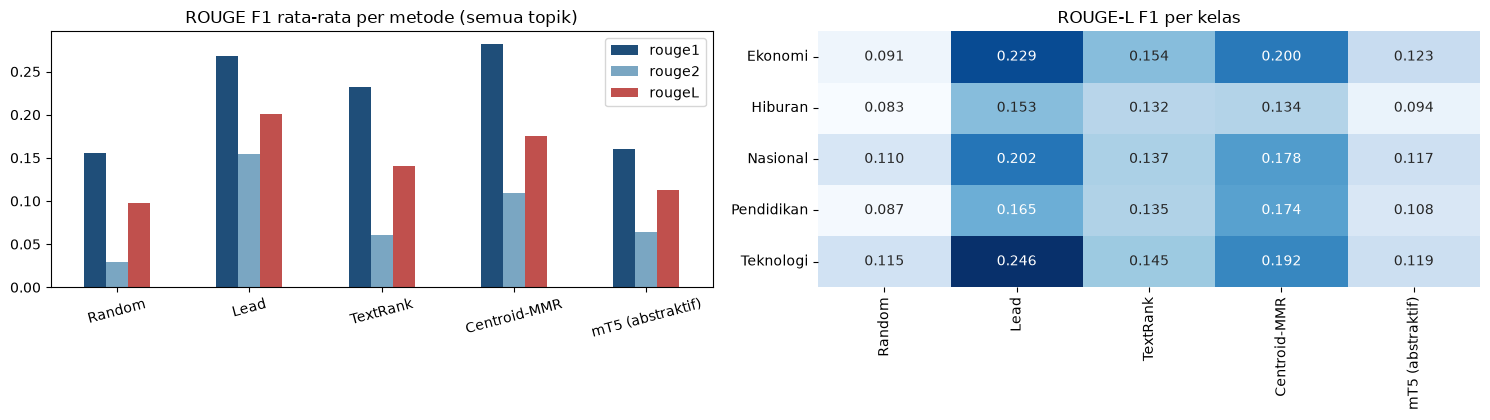

metode,Random,Lead,TextRank,Centroid-MMR,mT5 (abstraktif)
kelas,,,,,
Ekonomi,0.0906,0.2291,0.1538,0.2003,0.1228
Hiburan,0.0835,0.1533,0.1317,0.1342,0.0936
Nasional,0.1101,0.2024,0.1375,0.1778,0.1175
Pendidikan,0.0867,0.1646,0.1349,0.1738,0.1085
Teknologi,0.1149,0.2460,0.1446,0.1917,0.1191


In [6]:
by_class = rouge.pivot_table(index="kelas", columns="metode", values=["rouge1", "rouge2", "rougeL"])
by_class.to_csv(RES / "rouge_by_class.csv")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
overall[["rouge1", "rouge2", "rougeL"]].plot.bar(ax=ax[0], color=["#1f4e79", "#7aa6c2", "#c0504d"], rot=15)
ax[0].set_title("ROUGE F1 rata-rata per metode (semua topik)"); ax[0].set_xlabel("")
sns.heatmap(rouge.pivot_table(index="kelas", columns="metode", values="rougeL")[METHODS], annot=True, fmt=".3f",
            cmap="Blues", ax=ax[1], cbar=False)
ax[1].set_title("ROUGE-L F1 per kelas"); ax[1].set_xlabel(""); ax[1].set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "05_rouge.png", dpi=150); plt.show()
by_class["rougeL"][METHODS].round(4)

In [7]:
# Topik dengan ROUGE-L tertinggi & terendah (metode usulan) -> bahan analisis
mm = rouge[rouge.metode == "Centroid-MMR"].sort_values("rougeL")
print("ROUGE-L terendah:"); display(mm.head(4)[["kelas", "nama", "rouge1", "rouge2", "rougeL"]].round(3))
print("ROUGE-L tertinggi:"); display(mm.tail(4)[["kelas", "nama", "rouge1", "rouge2", "rougeL"]].round(3))

ROUGE-L terendah:


,kelas,nama,rouge1,rouge2,rougeL
113,Hiburan,Tips ChatGPT untuk karier & hidup,0.154,0.000,0.077
78,Hiburan,"AI, anak-anak & kehidupan sehari-hari",0.183,0.032,0.088
248,Teknologi,"Deepfake, penipuan & keamanan siber",0.252,0.031,0.099
58,Ekonomi,PHK Amazon demi investasi AI,0.220,0.074,0.106


ROUGE-L tertinggi:


,kelas,nama,rouge1,rouge2,rougeL
253,Teknologi,Google Gemini & Bard,0.388,0.258,0.281
218,Pendidikan,Inovasi aplikasi AI mahasiswa & dosen,0.345,0.174,0.290
223,Pendidikan,Kelas & kursus AI daring,0.394,0.237,0.318
163,Nasional,Video AI 'umrah ke Candi Borobudur',0.427,0.325,0.352


**Interpretasi ROUGE.**

- **Centroid-MMR (metode usulan)** mendapat **ROUGE-1 tertinggi** dari semua metode (0,282) dan recall
  ROUGE-1 tertinggi (0,198) — paling banyak memuat isi teras redaksi — serta jauh di atas Random
  (0,156 / 0,029 / 0,097) dan TextRank (0,232 / 0,061 / 0,141) di ketiga metrik.
- **Lead** unggul di ROUGE-2 (0,154) dan ROUGE-L (0,200). Ini bias yang sudah diperkirakan: referensi kita
  adalah **teras redaksi**, dan teras biasanya ditulis dari paragraf pertama berita, sehingga kalimat
  pembuka berbagi banyak bigram dan urutan kata yang persis sama (precision ROUGE-1 Lead 0,61). Lead
  hanya mengambil pembuka 3 artikel dan tidak menjamin isi topik terwakili. Di kelas Pendidikan, yang
  artikelnya lebih bersifat penjelasan, Centroid-MMR mengalahkan Lead di ROUGE-1, ROUGE-2, dan ROUGE-L.
- **TextRank** lebih rendah karena memilih kalimat yang paling "sentral" di antara kandidat; pada berita,
  kalimat sentral sering kalimat umum ("AI semakin berkembang …") yang tidak spesifik topik.
- **mT5 abstraktif** paling rendah di ROUGE-1 (0,161) karena ringkasannya pendek (±32 kata, recall rendah).
  Yang lebih penting, pemeriksaan manual menemukan **halusinasi fakta**: Eline van der Velden (pencipta
  Tilly Norwood) disebut sebagai "aktris berbasis AI", dan muncul tokoh "kepala Pusat Inovasi China, Yu
  Jinping" yang tidak ada di sumber. Untuk berita, ini kesalahan serius, sehingga metode ekstraktif dipilih
  sebagai metode akhir.

Nilai ROUGE absolut (±0,2–0,3) tampak rendah, tetapi wajar untuk peringkasan multi-dokumen dengan referensi
yang ditulis independen: ringkasan dan referensi bisa membahas fakta yang sama dengan kata berbeda (ROUGE
hanya mengukur kesamaan kata persis, tanpa stemming bahasa Indonesia).

## 4. Hasil: ringkasan per kelas dan per topik

Tabel berikut adalah keluaran utama Task 5 (format sesuai contoh pada soal: Kelas — Topik — Ringkasan).
Ringkasan memakai metode ekstraktif usulan (Centroid-MMR).

In [8]:
FINAL = "Centroid-MMR"
summary_table = pd.DataFrame([{
    "Kelas": u["kelas"], "Topik": f"Topik {u['topik']}: {u['nama']}", "Ringkasan": " ".join(u[FINAL]),
    "Ringkasan abstraktif (mT5)": u["mT5 (abstraktif)"][0],
} for u in units])
summary_table.to_csv(ROOT / "topic_summaries.csv", index=False, encoding="utf-8-sig")
for cls in CLASSES:
    print("\n" + "=" * 110 + f"\nKELAS: {cls.upper()}\n" + "=" * 110)
    for _, r in summary_table[summary_table.Kelas == cls].iterrows():
        print(f"\n▶ {r.Topik}\n{r.Ringkasan}")


KELAS: EKONOMI

▶ Topik 0: Transformasi digital & adopsi AI nasional
Dukungan terhadap Large Language Model (LLM) Bahasa Indonesia, penguatan keamanan data, serta pemanfaatan infrastruktur yang dibangun dan dioperasikan di dalam negeri mencerminkan komitmen Telkom dalam mendukung transformasi digital sekaligus memperkuat kedaulatan AI dan kedaulatan digital nasional. Direktur Jenderal Ekosistem Digital Kementerian Komunikasi dan Digital (Komdigi) Edwin Hidayat Abdullah mengatakan, Indonesia perlu berinvestasi dalam pengembangan insinyur AI, profesional keamanan siber, ilmuwan data, pembuat kebijakan, serta tenaga pendidik untuk memperkuat ekosistem digital nasional. Dengan portofolio solusi AI yang beragam, Telkom kini telah menjadi mitra strategis bagi berbagai sektor industri dalam meningkatkan efisiensi dan inovasi operasional, sekaligus memberikan kontribusi signifikan terhadap pertumbuhan ekonomi digital di Indonesia.

▶ Topik 1: Dampak AI pada pekerjaan & ekonomi
Pada akhirnya, 

**Interpretasi ringkasan.** Setiap ringkasan topik berisi kalimat yang spesifik dan faktual: misalnya
topik *Kasus deepfake mahasiswa Untan* memuat penanganan oleh Satgas PPKPT kampus, dan topik *AI di Bea
Cukai* memuat penerapan alat pemindai berbasis AI. Kelemahan yang masih terlihat: kalimat yang diambil di
tengah artikel kadang memuat rujukan yang menggantung ("Sebelumnya, ..."), dan ringkasan topik yang
berasal dari artikel promosi (*Kelas & kursus AI daring*) ikut bernada promosi.

## 5. Verifikasi cakupan topik (*topic coverage*)

Klaim utama Task 5: ringkasan kelas harus mewakili **setiap** topik utama. Kami mengujinya dengan
membandingkan dua ringkasan kelas yang **sama panjang** (jumlah kalimat sama):

- **Sadar-topik**: gabungan ringkasan per topik (di atas).
- **Tidak sadar-topik**: Centroid-MMR dijalankan sekali pada seluruh kelas memakai pusat **kelas**
  (rata-rata semua dokumen), tanpa informasi topik.

Sebuah topik dianggap **tercakup** bila ada minimal satu kalimat ringkasan yang (a) lebih mirip ke pusat
topik itu daripada ke pusat topik lain di kelas yang sama, dan (b) memuat minimal 2 dari 10 kata kunci
topik tersebut.

In [9]:
def covered_topics(sentences, cls):
    topics = [u for u in units if u["kelas"] == cls]
    C = np.stack([CENT[(cls, u["topik"])] for u in topics])
    E = embed(sentences)
    nearest = (E @ C.T).argmax(1)
    hit = set()
    for s, j in zip(sentences, nearest):
        if len(set(topics[j]["kw"]) & set(tokenize_phr(s))) >= 2:
            hit.add(topics[j]["topik"])
    return hit, len(topics)


cov_rows = []
for cls in CLASSES:
    tus = [u for u in units if u["kelas"] == cls]
    aware = [s for u in tus for s in u[FINAL]]
    # tidak sadar-topik: kandidat = kalimat dari dokumen yang paling dekat ke pusat KELAS
    sub = df[df.pred_label == cls]
    allc = pd.read_csv(ROOT / "dataset_classified.csv", usecols=["doc_id"])
    emb_all = np.load(MODELS / f"embeddings_minilm_{len(allc)}.npy")
    idx = allc.index[allc.doc_id.isin(sub.doc_id)]
    ccent = emb_all[idx].mean(0); ccent /= np.linalg.norm(ccent)
    order = np.argsort(-(emb_all[idx] @ ccent))[: N_DOCS * len(tus)]
    top_ids = allc.loc[idx[order], "doc_id"]
    cand = list(dict.fromkeys(s for b in sub.set_index("doc_id").loc[top_ids, "body_clean"] for s in split_sentences(b)[1:]))
    Ec = embed(cand)
    sim = Ec @ ccent
    agn = [cand[i] for i in mmr((sim - sim.min()) / (np.ptp(sim) + 1e-9), Ec, len(aware))]
    for name, sents in [("Sadar-topik", aware), ("Tidak sadar-topik", agn)]:
        hit, n = covered_topics(sents, cls)
        ref = " ".join(u["reference"] for u in tus)
        sc = scorer.score(ref, " ".join(sents))
        cov_rows.append({"kelas": cls, "ringkasan": name, "kalimat": len(sents), "topik_tercakup": len(hit),
                         "jumlah_topik": n, "coverage": len(hit) / n, "rouge1": sc["rouge1"].fmeasure,
                         "rouge2": sc["rouge2"].fmeasure, "rougeL": sc["rougeL"].fmeasure})
coverage = pd.DataFrame(cov_rows)
coverage.to_csv(RES / "topic_coverage.csv", index=False)
coverage.round(3)

,kelas,ringkasan,kalimat,topik_tercakup,jumlah_topik,coverage,rouge1,rouge2,rougeL
0,Ekonomi,Sadar-topik,36,12,12,1.000,0.435,0.175,0.209
1,Ekonomi,Tidak sadar-topik,36,2,12,0.167,0.340,0.071,0.102
2,Hiburan,Sadar-topik,36,12,12,1.000,0.360,0.093,0.140
3,Hiburan,Tidak sadar-topik,36,2,12,0.167,0.317,0.067,0.095
4,Nasional,Sadar-topik,36,12,12,1.000,0.405,0.137,0.180
5,Nasional,Tidak sadar-topik,36,1,12,0.083,0.292,0.068,0.089
6,Pendidikan,Sadar-topik,30,9,10,0.900,0.360,0.129,0.184
7,Pendidikan,Tidak sadar-topik,30,2,10,0.200,0.298,0.062,0.098
8,Teknologi,Sadar-topik,36,12,12,1.000,0.400,0.144,0.195
9,Teknologi,Tidak sadar-topik,36,3,12,0.250,0.326,0.058,0.104


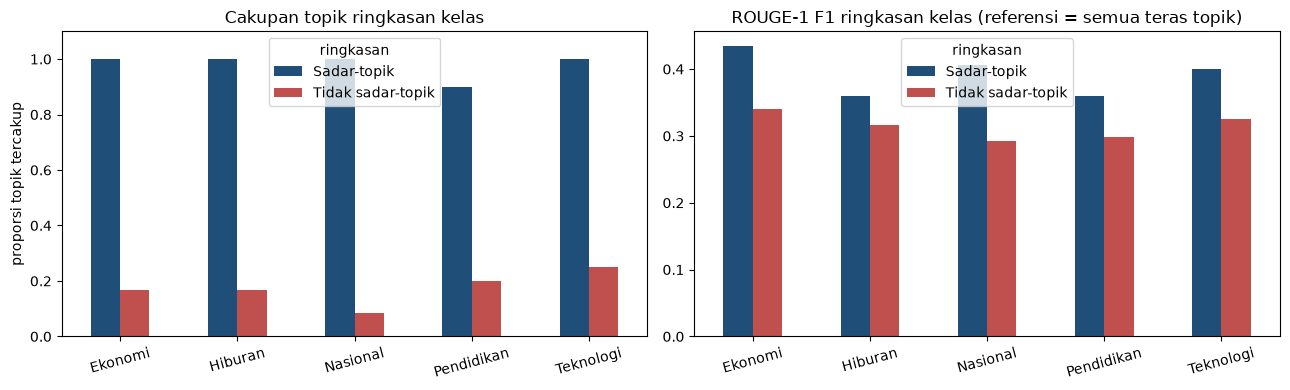

,coverage,rouge1,rouge2,rougeL
ringkasan,,,,
Sadar-topik,0.980,0.392,0.136,0.182
Tidak sadar-topik,0.173,0.314,0.065,0.098


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
coverage.pivot(index="kelas", columns="ringkasan", values="coverage").plot.bar(ax=ax[0], color=["#1f4e79", "#c0504d"], rot=15)
ax[0].set_title("Cakupan topik ringkasan kelas"); ax[0].set_ylim(0, 1.1); ax[0].set_xlabel(""); ax[0].set_ylabel("proporsi topik tercakup")
coverage.pivot(index="kelas", columns="ringkasan", values="rouge1").plot.bar(ax=ax[1], color=["#1f4e79", "#c0504d"], rot=15)
ax[1].set_title("ROUGE-1 F1 ringkasan kelas (referensi = semua teras topik)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "05_coverage.png", dpi=150); plt.show()
coverage.groupby("ringkasan")[["coverage", "rouge1", "rouge2", "rougeL"]].mean().round(3)

**Interpretasi cakupan topik.** Dengan jumlah kalimat yang **sama**, ringkasan sadar-topik mencakup
**57 dari 58 topik (98%)**, sedangkan ringkasan yang tidak sadar-topik hanya **10 dari 58 (17%)**: tanpa
informasi topik, MMR memilih kalimat dari tema paling dominan di kelas (hanya 1–3 topik per kelas yang
tersentuh), sehingga topik-topik kecil tidak terwakili. Ringkasan sadar-topik juga lebih mirip dengan
gabungan teras semua topik (ROUGE-1 0,392 vs 0,315; ROUGE-2 0,136 vs 0,065; ROUGE-L 0,182 vs 0,098),
artinya cakupan topik yang lebih luas juga berarti lebih banyak isi redaksi yang terambil.

Satu-satunya topik yang tidak lolos uji cakupan adalah *Prompt Gemini untuk foto wisuda & CV*
(Pendidikan): kalimatnya benar paling dekat ke topiknya, tetapi tiap kalimat hanya memuat 1 kata kunci,
di bawah ambang 2, karena kata kunci topik ini bercampur dengan kata lain (misalnya "superkomputer").
Ini menunjukkan kualitas ringkasan sadar-topik bergantung pada kualitas topiknya.

## Ringkasan Task 5

Ringkasan per kelas disusun dari ringkasan per topik (3 kalimat per topik) dengan metode ekstraktif
Centroid-MMR. Metode ini mendapat ROUGE-1 tertinggi, tidak mengarang fakta (berbeda dari mT5), dan
menghasilkan ringkasan kelas yang mencakup 98% topik — hampir enam kali lebih banyak daripada ringkasan
yang tidak sadar-topik dengan panjang yang sama.